In [9]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from src.tools.data_loader import get_dataloader, get_dataset_info
import sys
from src.config import get_config

In [10]:
config = get_config('sngan_celeba')
#config = get_config('sngan_celeba')

print(f"\n✅ Loaded config: {config.name}")
print(f"   {config.description}")
print(f"\n📊 Configuration details:")
print(f"   Dataset: {config.dataset_name} ({config.max_samples or 'all'} samples)")
print(f"   Image size: {config.image_size}x{config.image_size}")
print(f"   Batch size: {config.batch_size}")
print(f"   Use diffusion: {config.use_diffusion} (T_max={config.T_max})")
print(f"   Epochs: {config.num_epochs}, n_critic: {config.n_critic}")
print(f"   Learning rates: G={config.lr_g}, D={config.lr_d}")
print(f"   Adam betas: ({config.beta1}, {config.beta2})")
print(f"   Discriminator channels: {config.disc_channels}")
print(f"   Generator channels: {config.gen_channels}")


✅ Loaded config: sngan_celeba
   SNGAN for CelebA face generation (64x64 images)

📊 Configuration details:
   Dataset: celeba (10000 samples)
   Image size: 64x64
   Batch size: 64
   Use diffusion: False (T_max=0)
   Epochs: 200, n_critic: 2
   Learning rates: G=0.0002, D=0.0002
   Adam betas: (0.0, 0.9)
   Discriminator channels: [16, 32, 64, 128]
   Generator channels: [128, 64, 32, 16]


In [11]:
info = get_dataset_info(config.dataset_name)
print(f"Dataset: {info['name']}")
print(f"Description: {info['description']}")
print(f"Number of classes: {info['num_classes']}")

# Configuration pour le téléchargement
# Pour CelebA: mettre download=False si vous avez téléchargé manuellement
auto_download = config.dataset_name != 'celeba'  # Évite les erreurs Google Drive

# Load dataloaders avec image_size
print(f"🔍 Debug: dataset={config.dataset_name}, image_size={config.image_size}")
train_loader, num_classes, image_shape = get_dataloader(
    dataset_name=config.dataset_name,
    data_dir=config.data_dir,
    batch_size=config.batch_size,
    train=True,
    shuffle=True,
    max_samples=config.max_samples,
    image_size=config.image_size,
    download=False  # False pour CelebA par défaut
)

test_loader, _, _ = get_dataloader(
    dataset_name=config.dataset_name,
    data_dir=config.data_dir,
    batch_size=config.batch_size,
    train=False,
    shuffle=False,
    max_samples=config.max_samples,
    image_size=config.image_size,
    download=auto_download
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")
if config.max_samples:
    print(f"⚡ Limited to {config.max_samples} samples per dataset")

# Vérifier la taille réelle des images dans le dataloader
print(f"\n🔍 Debug: Testing first batch...")
x_check, _ = next(iter(train_loader))
print(f"🔍 Debug: x_check type = {type(x_check)}, shape = {x_check.shape if hasattr(x_check, 'shape') else 'NO SHAPE'}")
actual_size = x_check.shape[2]  # height
print(f"\n✅ Taille réelle des images dans le dataloader: {actual_size}x{actual_size}")

Dataset: CelebA
Description: Celebrity faces dataset (202,599 face images of celebrities)
Number of classes: 1
🔍 Debug: dataset=celeba, image_size=64
⚠️  Using direct image loading for CelebA (metadata .txt not found)
📁 Loading images from: ./data\celeba\img_align_celeba
⚠️  Using direct image loading for CelebA (metadata .txt not found)
📁 Loading images from: ./data\celeba\img_align_celeba

Train batches: 157
Test batches: 157
⚡ Limited to 10000 samples per dataset

🔍 Debug: Testing first batch...
🔍 Debug: x_check type = <class 'torch.Tensor'>, shape = torch.Size([64, 3, 64, 64])

✅ Taille réelle des images dans le dataloader: 64x64


In [12]:
import importlib
import sys

# Force reload des modules
if 'src.models.SNGAN_disc' in sys.modules:
    del sys.modules['src.models.SNGAN_disc']
if 'src.models.SNGAN_gen' in sys.modules:
    del sys.modules['src.models.SNGAN_gen']
if 'src.models.gan_factory' in sys.modules:
    del sys.modules['src.models.gan_factory']

import src.models.gan_factory as gan_factory

print(f"Configuration:")
print(f"  - Image size: {config.image_size}x{config.image_size}")
print(f"  - Gen channels: {config.gen_channels}")
print(f"  - Disc channels: {config.disc_channels}")

def count_parameters(model, name="Modele"):
    """Compte et affiche le nombre de paramètres entraînables."""
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"📊 {name}: {total_params:,} paramètres")
    return total_params

generator, discriminator = gan_factory.create_gan_models(
    variant=config.variant,
    use_diffusion=config.use_diffusion,
    image_channels=1 if info['grayscale'] else 3,
    z_dim=config.z_dim,
    time_embedding_dim=config.time_embedding_dim,
    gen_channels=config.gen_channels,
    disc_channels=config.disc_channels,
    image_size=config.image_size  # IMPORTANT: Passer la taille d'image
)

# VÉRIFICATION: Test rapide des dimensions
with torch.no_grad():
    z_test = torch.randn(2, config.z_dim)
    out_test = generator(z_test)
    print(f"✅ Générateur produit des images: {out_test.shape[2]}x{out_test.shape[3]}")

p_G = count_parameters(generator, "Générateur")
p_D = count_parameters(discriminator, "Discriminateur")
print(f"👉 TOTAL: {p_G + p_D:,} paramètres")

Configuration:
  - Image size: 64x64
  - Gen channels: [128, 64, 32, 16]
  - Disc channels: [16, 32, 64, 128]
disc_channels: [16, 32, 64, 128]
[Discriminator] conv_channels=[16, 32, 64, 128], use_diffusion=False
✅ Générateur produit des images: 64x64
📊 Générateur: 426,547 paramètres
📊 Discriminateur: 616,305 paramètres
👉 TOTAL: 1,042,852 paramètres


## 📂 Chargement et Entraînement

- **Cellule suivante** : Charge automatiquement le checkpoint si existant
- **Cellule d'après** : Lance/reprend l'entraînement (reprend là où ça en était)

💡 **Un modèle par config** : Le checkpoint est lié au nom de la config (`sngan_celeba`, etc.)

In [13]:
# 🔄 Chargement du checkpoint (si existant)
import importlib
import src.tools.model_loader
importlib.reload(src.tools.model_loader)
from src.tools.model_loader import load_for_inference, checkpoint_exists, get_checkpoint_info

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if checkpoint_exists(config):
    info = get_checkpoint_info(config)
    epoch = load_for_inference(config, generator, discriminator, device)
    print(f"✅ Checkpoint '{config.name}' chargé (epoch {epoch + 1})")
else:
    print(f"ℹ️  Aucun checkpoint pour '{config.name}' - modèle non entraîné")

✅ Checkpoint 'sngan_celeba' chargé (epoch 22)


In [14]:
# 🚀 Entraînement (reprend automatiquement si checkpoint existant)
import importlib
import src.trainer
importlib.reload(src.trainer)
from src.trainer import Trainer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

trainer = Trainer(
    generator=generator,
    discriminator=discriminator,
    config=config,
    train_loader=train_loader,
    device=device,
    resume=True  # Reprend le checkpoint s'il existe
)

history = trainer.train()

# Modèles entraînés disponibles
generator = trainer.generator
discriminator = trainer.discriminator

📊 TensorBoard: tensorboard --logdir=./runs
📁 Run: sngan_celeba
⚙️  Config: sngan_celeba
🔄 Resuming from epoch 22 (step 3454)

CUDA available: True
CUDA device: NVIDIA GeForce RTX 5070
Using device: cuda

🎯 Loss function: HINGE

🎯 Training configuration:
   Image size: 64x64
   Batch size: 64
   Epochs: 22 → 200
   n_critic: 2
   LR: G=0.0002, D=0.0002



Epoch [ 25/200]: 100%|████████████████████████████| 157/157 [00:31<00:00,  5.05batch/s, D_loss=0.9243, G_loss=0.2442, D_acc=0.757]


   📊 Validation: Std=0.6015, Diversity=0.3951


Epoch [ 30/200]: 100%|████████████████████████████| 157/157 [00:30<00:00,  5.09batch/s, D_loss=0.8761, G_loss=0.3168, D_acc=0.776]


   📊 Validation: Std=0.5957, Diversity=0.3671

📏 Computing FID (epoch 30)...


...

   📊 Validation: Std=0.5382, Diversity=0.3519


Epoch [200/200]: 100%|████████████████████████████| 157/157 [00:31<00:00,  5.05batch/s, D_loss=0.3725, G_loss=2.1065, D_acc=0.921]


   📊 Validation: Std=0.5669, Diversity=0.3770

📏 Computing FID (epoch 200)...


100%|██████████| 100/100 [00:45<00:00,  2.20it/s]


   FID: 46.58

✅ Training complete! Checkpoint saved to ./models/
📊 View results: tensorboard --logdir=./runs
🖼️  Image grids saved to ./runs\sngan_celeba\samples/


## TensorBoard

Lance cette commande dans le terminal pour voir les losses en temps réel:
```bash
tensorboard --logdir ./runs
```

Puis ouvre http://localhost:6006 dans le navigateur.

Quick visual test: sngan_celeba



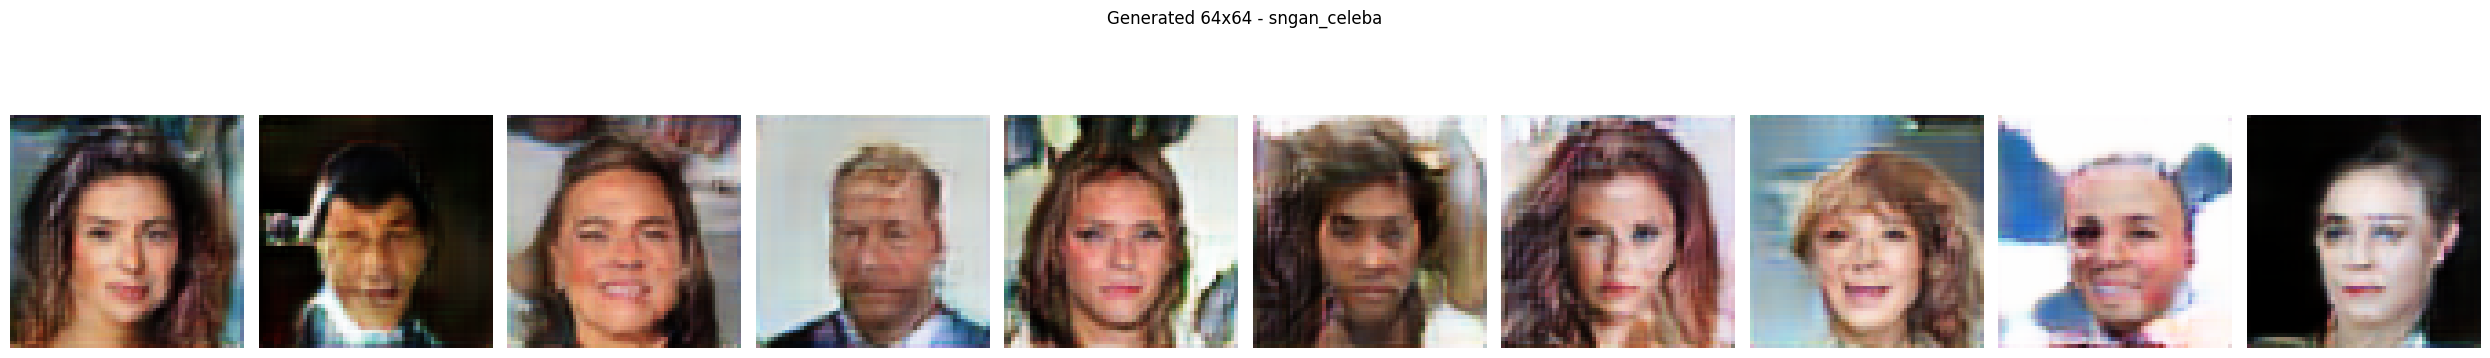

Diversity ratio: 0.3972


In [16]:
# 🚀 Test rapide: Génération sans FID (pour vérifier visuellement)

from src.tools.model_tester import test_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Quick visual test: {config.name}\n")

# Test rapide sans calcul FID
results = test_model(
    generator=generator,
    dataloader=train_loader,
    config=config,
    device=device,
    num_images=10,
    calculate_fid_score=False  # Désactiver FID pour test rapide
)

In [17]:
# ✅ Vérification de la configuration FID

print("📊 Configuration FID:")
print(f"   Activé: {config.compute_fid}")
print(f"   Fréquence: toutes les {config.fid_frequency} epochs")
print(f"   Échantillons: {config.fid_num_samples}")
print()

if config.compute_fid:
    print("✅ Le FID sera calculé automatiquement pendant l'entraînement!")
    print("   Les résultats seront visibles dans TensorBoard (Metrics/FID)")
else:
    print("⚠️  Le FID n'est pas activé. Pour l'activer:")
    print("   config.compute_fid = True")

📊 Configuration FID:
   Activé: True
   Fréquence: toutes les 10 epochs
   Échantillons: 5000

✅ Le FID sera calculé automatiquement pendant l'entraînement!
   Les résultats seront visibles dans TensorBoard (Metrics/FID)
